# CHATBOT CIMA — Actividad 6
## Evaluación, validación y ajuste de decisiones

Este notebook evalúa los modelos congelados de la Actividad 5 y produce evidencia reproducible para el reporte y el tablero Trello.

**Flujo:** matrices de confusión → métricas y ROC/AUC → baseline → validación cruzada OOF de cuatro pliegues → umbral derivado de OOF → comparación estadística pareada → simulación offline de políticas A/B.

> **Límite de interpretación:** el dataset es sintético; la partición de prueba tiene 26 registros y solo 2 casos `AMBIGUA`. Los resultados son exploratorios y no autorizan el uso productivo ni validaciones de pagos.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alfredosalazar-ai/deep-learning-experiments/blob/main/Actividad6/fuentes/CIMA_Actividad6_Evaluacion_Validacion.ipynb)


## 1. Preparar el entorno y ubicar el proyecto

La versión pública del proyecto se obtiene desde GitHub. Mientras la carpeta `Actividad6/` aún no esté publicada, se puede cargar el ZIP de preparación de esta actividad. No se necesita instalar nada en la computadora local.

In [3]:
%pip install -q "scikit-learn==1.6.1" "joblib>=1.4,<2" "mlflow==3.17.1"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 1.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 72.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 86.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 83.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.4/270.4 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
import sys
import sklearn
import joblib
import mlflow

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)
print("MLflow:", mlflow.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
scikit-learn: 1.6.1
joblib: 1.6.0
MLflow: 3.17.1


In [7]:
from pathlib import Path
import joblib
import sklearn

print("scikit-learn:", sklearn.__version__)

# Ajusta ROOT si el proyecto quedó en otra ubicación de Colab
ROOT = Path("/content/Actividad6")

for nombre in ["Regresion_Logistica.joblib", "LinearSVC.joblib"]:
    coincidencias = list(
        Path("/content").rglob(nombre)
    )
    print(nombre, "->", coincidencias[:3])

scikit-learn: 1.6.1
Regresion_Logistica.joblib -> [PosixPath('/content/deep-learning-experiments/Actividad6/modelos/Regresion_Logistica.joblib'), PosixPath('/content/deep-learning-experiments/Actividad5/resultados/entrenamiento/modelos/Regresion_Logistica.joblib')]
LinearSVC.joblib -> [PosixPath('/content/deep-learning-experiments/Actividad6/modelos/LinearSVC.joblib'), PosixPath('/content/deep-learning-experiments/Actividad5/resultados/entrenamiento/modelos/LinearSVC.joblib')]


In [8]:
from pathlib import Path
import joblib
import sklearn
import pandas as pd

ROOT = Path("/content/deep-learning-experiments/Actividad6")
MODELS_DIR = ROOT / "modelos"
DATA_PATH = ROOT / "datos" / "datos_limp" / "cima_consultas_limpias.csv"

print("scikit-learn:", sklearn.__version__)
print("Dataset disponible:", DATA_PATH.exists())

for nombre in ["Regresion_Logistica.joblib", "LinearSVC.joblib"]:
    ruta = MODELS_DIR / nombre
    assert ruta.exists(), f"No se encontró: {ruta}"

    modelo = joblib.load(ruta)
    print(f"\nModelo cargado: {nombre}")
    print("Tipo:", type(modelo).__name__)
    print("Clases:", list(modelo.classes_))

scikit-learn: 1.6.1
Dataset disponible: True

Modelo cargado: Regresion_Logistica.joblib
Tipo: Pipeline
Clases: [np.str_('AMBIGUA'), np.str_('FUERA_ALCANCE'), np.str_('INDIVIDUAL'), np.str_('PAQUETE')]

Modelo cargado: LinearSVC.joblib
Tipo: Pipeline
Clases: [np.str_('AMBIGUA'), np.str_('FUERA_ALCANCE'), np.str_('INDIVIDUAL'), np.str_('PAQUETE')]


In [9]:

from pathlib import Path
import pandas as pd
import joblib
import sklearn

ROOT = Path("/content/deep-learning-experiments/Actividad6")
MODELS_DIR = ROOT / "modelos"
DATA_PATH = ROOT / "datos" / "datos_limp" / "cima_consultas_limpias.csv"

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

print("Columnas del dataset:")
print(df.columns.tolist())

print("\nRegistros:", len(df))
print("\nDistribución de particiones:")
if "particion_a5" in df.columns:
    print(df["particion_a5"].value_counts())
elif "particion" in df.columns:
    print(df["particion"].value_counts())
else:
    print("No se encontró una columna de partición.")

print("\nDistribución de clases:")
print(df["clase_real"].value_counts())

display(df.head())


Columnas del dataset:
['id', 'texto', 'clase_real', 'subtipo', 'dificultad', 'particion', 'justificacion', 'texto_normalizado', 'particion_a5', 'version_dataset']

Registros: 128

Distribución de particiones:
particion_a5
entrenamiento    102
prueba            26
Name: count, dtype: int64

Distribución de clases:
clase_real
INDIVIDUAL       40
FUERA_ALCANCE    40
PAQUETE          38
AMBIGUA          10
Name: count, dtype: int64


,id,texto,clase_real,subtipo,dificultad,particion,justificacion,texto_normalizado,particion_a5,version_dataset
0,CIMA-001,Hay un SPEI pendiente de identificación. ¿Se p...,AMBIGUA,sin_folio,media,evaluacion,No hay un folio único identificable o el estad...,Hay un SPEI pendiente de identificación. ¿Se p...,entrenamiento,a5-v1.0
1,CIMA-002,"Solicito confirmar este depósito, pero todavía...",AMBIGUA,sin_folio,media,evaluacion,No hay un folio único identificable o el estad...,"Solicito confirmar este depósito, pero todavía...",prueba,a5-v1.0
2,CIMA-003,¿Qué significa esta referencia CIE? No sé a qu...,AMBIGUA,sin_folio,media,desarrollo,No hay un folio único identificable o el estad...,¿Qué significa esta referencia CIE? No sé a qu...,entrenamiento,a5-v1.0
3,CIMA-004,Aparece VALIDACIÓN Pendiente y el movimiento e...,AMBIGUA,sin_folio,media,desarrollo,No hay un folio único identificable o el estad...,Aparece VALIDACIÓN Pendiente y el movimiento e...,entrenamiento,a5-v1.0
4,CIMA-005,"Necesito saber si fue anticipo o finiquito, pe...",AMBIGUA,pendiente_asignacion,alta,evaluacion,No hay un folio único identificable o el estad...,"Necesito saber si fue anticipo o finiquito, pe...",entrenamiento,a5-v1.0


,modelo,accuracy,precision_macro,recall_macro,f1_macro,latencia_ms_por_texto,falsas_elegibilidades,casos_no_individuales,roc_auc_ovr_macro,roc_auc_individual_vs_resto
0,Regresion_Logistica,1.0000,1.0000,1.000,1.0000,0.7754,0,18,1.0,1.0
1,LinearSVC,0.9615,0.9722,0.875,0.9020,0.1074,1,18,1.0,1.0
2,Baseline_mayoria,0.3077,0.0769,0.250,0.1176,NaN,0,18,NaN,NaN


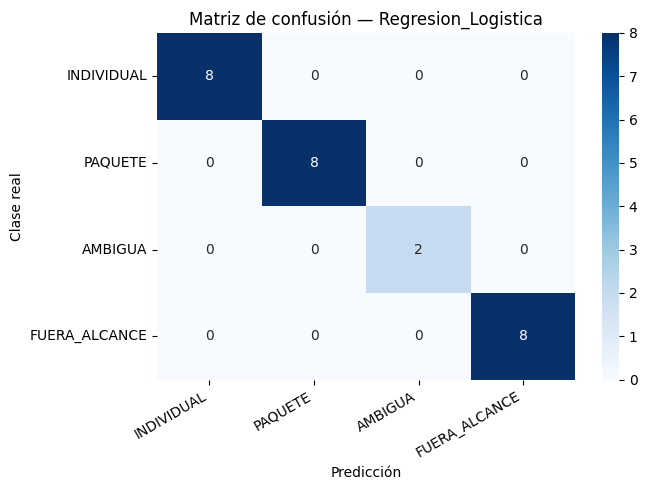

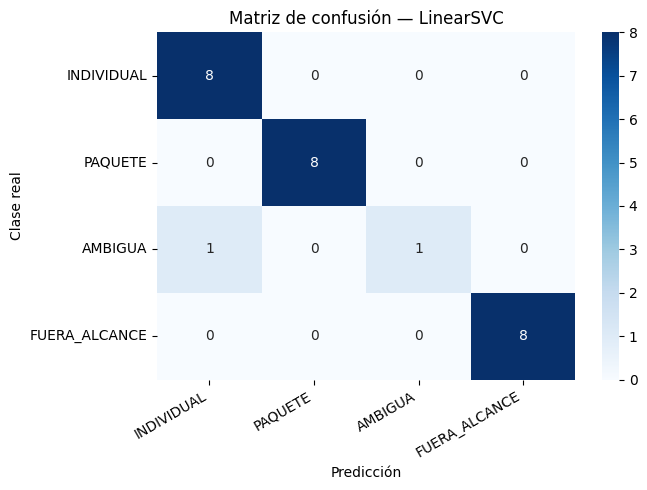

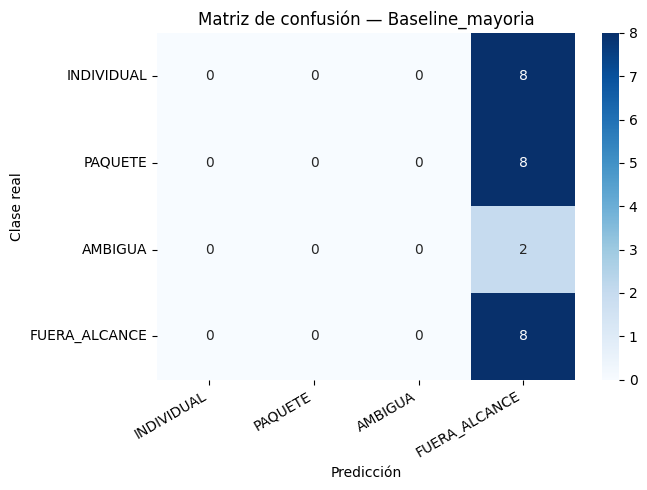


Prueba reservada: 26 registros
Resultados guardados en: /content/deep-learning-experiments/Actividad6/resultados/evaluacion_inicial
Umbral: decisión original de cada clasificador; aún no ajustado.


In [10]:

from pathlib import Path
import json
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
)
from sklearn.preprocessing import label_binarize

# --------------------------------------------------
# 1. Rutas y datos
# --------------------------------------------------
ROOT = Path("/content/deep-learning-experiments/Actividad6")
MODELS_DIR = ROOT / "modelos"
DATA_PATH = ROOT / "datos" / "datos_limp" / "cima_consultas_limpias.csv"
RESULTS_DIR = ROOT / "resultados" / "evaluacion_inicial"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

train = df[df["particion_a5"] == "entrenamiento"].copy()
test = df[df["particion_a5"] == "prueba"].copy()

assert len(train) == 102 and len(test) == 26
assert not (
    set(train["texto_normalizado"].str.casefold())
    & set(test["texto_normalizado"].str.casefold())
), "Se detectaron textos compartidos entre entrenamiento y prueba."

X_train = train["texto_normalizado"].astype(str)
y_train = train["clase_real"].astype(str)
X_test = test["texto_normalizado"].astype(str)
y_test = test["clase_real"].astype(str)

CLASSES = [
    "INDIVIDUAL",
    "PAQUETE",
    "AMBIGUA",
    "FUERA_ALCANCE",
]
POSITIVE_CLASS = "INDIVIDUAL"

# --------------------------------------------------
# 2. Baseline: clase mayoritaria del entrenamiento
# --------------------------------------------------
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
pred_baseline = baseline.predict(X_test)

# --------------------------------------------------
# 3. Evaluar modelos originales sin cambiar umbrales
# --------------------------------------------------
model_files = {
    "Regresion_Logistica": MODELS_DIR / "Regresion_Logistica.joblib",
    "LinearSVC": MODELS_DIR / "LinearSVC.joblib",
}

models = {}
predictions = {}
scores = {}
metrics = []
confusion_matrices = {}

for name, path in model_files.items():
    assert path.is_file(), f"No se encontró el modelo: {path}"

    model = joblib.load(path)
    models[name] = model

    start = time.perf_counter()
    pred = model.predict(X_test)
    elapsed_ms = (time.perf_counter() - start) * 1000 / len(X_test)

    predictions[name] = pred

    row = {
        "modelo": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision_macro": precision_score(
            y_test, pred, labels=CLASSES,
            average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            y_test, pred, labels=CLASSES,
            average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            y_test, pred, labels=CLASSES,
            average="macro", zero_division=0
        ),
        "latencia_ms_por_texto": elapsed_ms,
        "falsas_elegibilidades": int(
            sum(
                real != POSITIVE_CLASS and estimada == POSITIVE_CLASS
                for real, estimada in zip(y_test, pred)
            )
        ),
        "casos_no_individuales": int(
            (y_test != POSITIVE_CLASS).sum()
        ),
    }

    # Puntajes para ROC-AUC; no se interpretan como
    # probabilidades calibradas en LinearSVC.
    if hasattr(model, "predict_proba"):
        score_matrix = model.predict_proba(X_test)
    else:
        score_matrix = model.decision_function(X_test)

    model_classes = list(model.classes_)
    scores[name] = score_matrix

    y_bin = label_binarize(y_test, classes=model_classes)

    try:
        row["roc_auc_ovr_macro"] = roc_auc_score(
            y_bin,
            score_matrix,
            average="macro",
        )
    except ValueError:
        row["roc_auc_ovr_macro"] = np.nan

    positive_index = model_classes.index(POSITIVE_CLASS)
    if score_matrix.ndim == 2 and score_matrix.shape[1] == len(model_classes):
        positive_score = score_matrix[:, positive_index]
        y_binary = (y_test == POSITIVE_CLASS).astype(int)

        try:
            row["roc_auc_individual_vs_resto"] = roc_auc_score(
                y_binary, positive_score
            )
        except ValueError:
            row["roc_auc_individual_vs_resto"] = np.nan
    else:
        row["roc_auc_individual_vs_resto"] = np.nan

    metrics.append(row)
    confusion_matrices[name] = confusion_matrix(
        y_test, pred, labels=CLASSES
    )

# --------------------------------------------------
# 4. Métricas del baseline
# --------------------------------------------------
metrics.append({
    "modelo": "Baseline_mayoria",
    "accuracy": accuracy_score(y_test, pred_baseline),
    "precision_macro": precision_score(
        y_test, pred_baseline, labels=CLASSES,
        average="macro", zero_division=0
    ),
    "recall_macro": recall_score(
        y_test, pred_baseline, labels=CLASSES,
        average="macro", zero_division=0
    ),
    "f1_macro": f1_score(
        y_test, pred_baseline, labels=CLASSES,
        average="macro", zero_division=0
    ),
    "latencia_ms_por_texto": np.nan,
    "falsas_elegibilidades": int(
        sum(
            real != POSITIVE_CLASS and estimada == POSITIVE_CLASS
            for real, estimada in zip(y_test, pred_baseline)
        )
    ),
    "casos_no_individuales": int(
        (y_test != POSITIVE_CLASS).sum()
    ),
    "roc_auc_ovr_macro": np.nan,
    "roc_auc_individual_vs_resto": np.nan,
})

confusion_matrices["Baseline_mayoria"] = confusion_matrix(
    y_test, pred_baseline, labels=CLASSES
)

metrics_df = pd.DataFrame(metrics)
metrics_df.to_csv(
    RESULTS_DIR / "metricas_iniciales.csv",
    index=False,
    encoding="utf-8-sig",
)

display(metrics_df.round(4))

# --------------------------------------------------
# 5. Matrices de confusión y reportes por clase
# --------------------------------------------------
pred_rows = []

for name, pred in {
    **predictions,
    "Baseline_mayoria": pred_baseline,
}.items():
    for rid, texto, real, estimada in zip(
        test["id"], X_test, y_test, pred
    ):
        pred_rows.append({
            "modelo": name,
            "id": rid,
            "texto": texto,
            "clase_real": real,
            "prediccion": estimada,
            "falsa_elegibilidad": (
                real != POSITIVE_CLASS and estimada == POSITIVE_CLASS
            ),
        })

    cm = confusion_matrices[name]

    fig, ax = plt.subplots(figsize=(7, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        ax=ax,
    )
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Clase real")
    ax.set_title(f"Matriz de confusión — {name}")
    plt.xticks(rotation=30, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()

    filename = f"matriz_{name.lower()}.png"
    fig.savefig(RESULTS_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    reporte = classification_report(
        y_test, pred,
        labels=CLASSES,
        zero_division=0,
        output_dict=True,
    )
    with open(
        RESULTS_DIR / f"reporte_{name.lower()}.json",
        "w", encoding="utf-8"
    ) as f:
        json.dump(reporte, f, ensure_ascii=False, indent=2)

predictions_df = pd.DataFrame(pred_rows)
predictions_df.to_csv(
    RESULTS_DIR / "predicciones_iniciales.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nPrueba reservada:", len(test), "registros")
print("Resultados guardados en:", RESULTS_DIR)
print("Umbral: decisión original de cada clasificador; aún no ajustado.")


In [11]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

THRESHOLD_DIR = RESULTS_DIR / "umbrales"
THRESHOLD_DIR.mkdir(parents=True, exist_ok=True)

SEED = 20261015
CV = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEED
)

POS = "INDIVIDUAL"
y_train_bin = (y_train == POS).astype(int)
y_test_bin = (y_test == POS).astype(int)

threshold_results = []
threshold_predictions = {}

def obtener_puntaje_individual(modelo, X, nombre):
    """Puntaje usado para decidir si aceptar INDIVIDUAL."""
    clases = list(modelo.classes_)
    idx = clases.index(POS)

    if nombre == "Regresion_Logistica":
        # Probabilidad estimada de INDIVIDUAL.
        return modelo.predict_proba(X)[:, idx]

    # LinearSVC: margen de INDIVIDUAL frente a la
    # mayor puntuación de las clases alternativas.
    scores = modelo.decision_function(X)
    otras = np.delete(scores, idx, axis=1)
    return scores[:, idx] - np.max(otras, axis=1)


for nombre, modelo_original in models.items():

    # OOF: cada puntaje de entrenamiento procede de un
    # modelo que no entrenó con ese mismo registro.
    modelo_cv = clone(modelo_original)

    if nombre == "Regresion_Logistica":
        scores_oof = cross_val_predict(
            modelo_cv,
            X_train,
            y_train,
            cv=CV,
            method="predict_proba",
            n_jobs=-1,
        )
        idx = list(modelo_original.classes_).index(POS)
        scores_oof = scores_oof[:, idx]

        # Mismo sistema de puntuación en la prueba.
        score_test = obtener_puntaje_individual(
            modelo_original, X_test, nombre
        )

    else:
        scores_oof = cross_val_predict(
            modelo_cv,
            X_train,
            y_train,
            cv=CV,
            method="decision_function",
            n_jobs=-1,
        )
        clases = list(modelo_original.classes_)
        idx = clases.index(POS)

        scores_oof = (
            scores_oof[:, idx]
            - np.max(np.delete(scores_oof, idx, axis=1), axis=1)
        )

        score_test = obtener_puntaje_individual(
            modelo_original, X_test, nombre
        )

    # Seleccionar el umbral con los casos NO INDIVIDUALES
    # de entrenamiento OOF. No se usa y_test para elegirlo.
    mascara_no_ind = (y_train.to_numpy() != POS)

    max_score_no_ind = np.max(scores_oof[mascara_no_ind])
    threshold = np.nextafter(max_score_no_ind, np.inf)

    # Política de abstención: solo aceptar INDIVIDUAL
    # si supera el umbral; el resto pasa a revisión.
    aceptado_test = score_test >= threshold
    pred_threshold = np.where(
        aceptado_test,
        POS,
        "REVISION_HUMANA"
    )

    threshold_predictions[nombre] = pred_threshold

    false_accept_oof = int(
        np.sum(scores_oof[mascara_no_ind] >= threshold)
    )

    mascara_ind_test = (y_test.to_numpy() == POS)
    aceptados_ind = int(
        np.sum(aceptado_test & mascara_ind_test)
    )

    false_accept_test = int(
        np.sum(aceptado_test & ~mascara_ind_test)
    )

    metricas = {
        "modelo": nombre,
        "puntaje": (
            "probabilidad_individual"
            if nombre == "Regresion_Logistica"
            else "margen_individual_vs_resto"
        ),
        "umbral_seleccionado": float(threshold),
        "falsas_aceptaciones_oof": false_accept_oof,
        "individuales_aceptados_test": aceptados_ind,
        "total_individuales_test": int(mascara_ind_test.sum()),
        "falsas_aceptaciones_test": false_accept_test,
        "casos_enviados_a_revision_test": int(
            np.sum(~aceptado_test)
        ),
        "cobertura_total_test": float(np.mean(aceptado_test)),
    }

    threshold_results.append(metricas)

threshold_df = pd.DataFrame(threshold_results)

threshold_df.to_csv(
    THRESHOLD_DIR / "resumen_umbrales.csv",
    index=False,
    encoding="utf-8-sig",
)

display(threshold_df.round(4))

# Guardar la clasificación con abstención para análisis.
filas = []
for nombre, pred in threshold_predictions.items():
    for rid, real, decision in zip(
        test["id"], y_test, pred
    ):
        filas.append({
            "modelo": nombre,
            "id": rid,
            "clase_real": real,
            "decision_umbral": decision,
            "falsa_elegibilidad": (
                real != POS and decision == POS
            ),
        })

pd.DataFrame(filas).to_csv(
    THRESHOLD_DIR / "decisiones_umbral_test.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Resultados de umbrales guardados en:", THRESHOLD_DIR)


,modelo,puntaje,umbral_seleccionado,falsas_aceptaciones_oof,individuales_aceptados_test,total_individuales_test,falsas_aceptaciones_test,casos_enviados_a_revision_test,cobertura_total_test
0,Regresion_Logistica,probabilidad_individual,0.2731,0,8,8,0,18,0.3077
1,LinearSVC,margen_individual_vs_resto,0.5049,0,8,8,0,18,0.3077


Resultados de umbrales guardados en: /content/deep-learning-experiments/Actividad6/resultados/evaluacion_inicial/umbrales


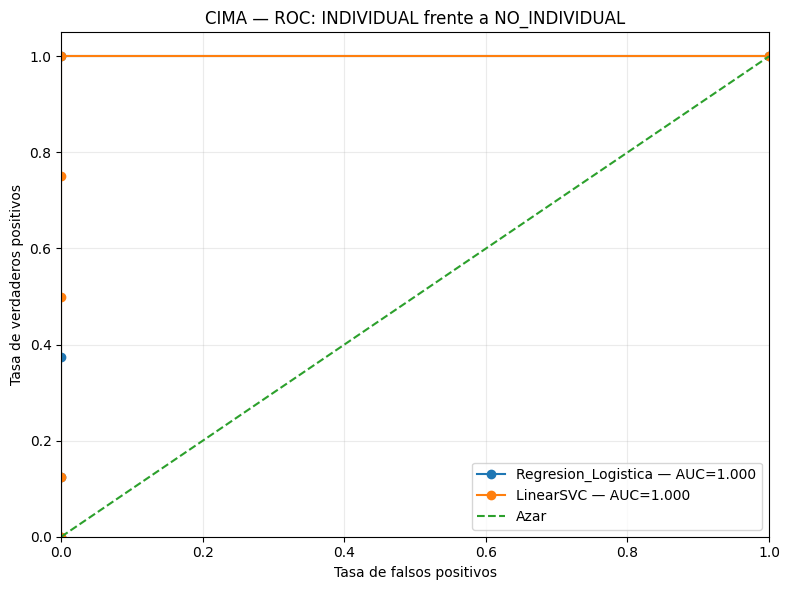

,modelo,umbral_seleccionado,falsas_aceptaciones_test,casos_enviados_a_revision_test,cobertura_total_test
0,Regresion_Logistica,0.273113,0,18,0.307692
1,LinearSVC,0.504938,0,18,0.307692


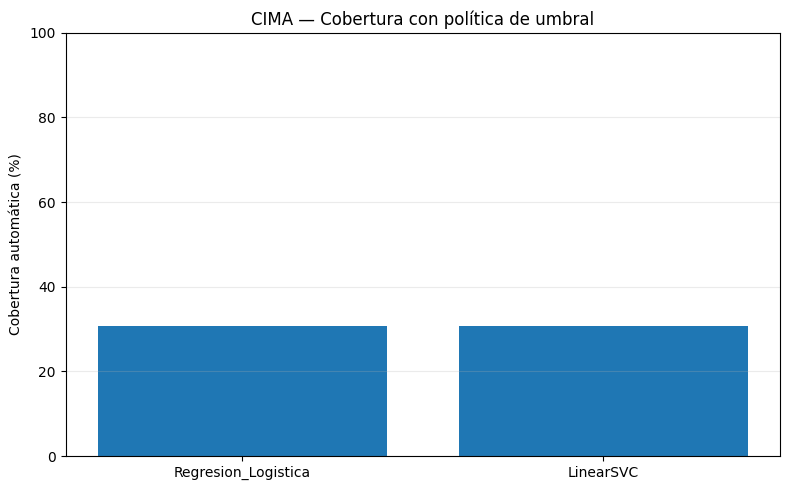

ROC y visualizaciones guardadas en: /content/deep-learning-experiments/Actividad6/resultados/evaluacion_inicial/roc


In [12]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
)

ROC_DIR = RESULTS_DIR / "roc"
ROC_DIR.mkdir(parents=True, exist_ok=True)

y_test_bin = (y_test.to_numpy() == "INDIVIDUAL").astype(int)

# 1. ROC: INDIVIDUAL frente a NO_INDIVIDUAL
fig, ax = plt.subplots(figsize=(8, 6))
roc_rows = []

for nombre, modelo in models.items():
    clases = list(modelo.classes_)
    idx = clases.index("INDIVIDUAL")

    if hasattr(modelo, "predict_proba"):
        puntaje = modelo.predict_proba(X_test)[:, idx]
        tipo_puntaje = "probabilidad"
    else:
        puntajes = modelo.decision_function(X_test)
        puntaje = (
            puntajes[:, idx]
            - np.max(np.delete(puntajes, idx, axis=1), axis=1)
        )
        tipo_puntaje = "margen"

    fpr, tpr, thresholds = roc_curve(y_test_bin, puntaje)
    auc = roc_auc_score(y_test_bin, puntaje)

    ax.plot(
        fpr, tpr,
        marker="o",
        label=f"{nombre} — AUC={auc:.3f}"
    )

    for f, t, th in zip(fpr, tpr, thresholds):
        roc_rows.append({
            "modelo": nombre,
            "tipo_puntaje": tipo_puntaje,
            "fpr": f,
            "tpr": t,
            "umbral_roc": th,
            "auc": auc,
        })

ax.plot([0, 1], [0, 1], linestyle="--", label="Azar")
ax.set(
    xlabel="Tasa de falsos positivos",
    ylabel="Tasa de verdaderos positivos",
    title="CIMA — ROC: INDIVIDUAL frente a NO_INDIVIDUAL",
    xlim=(0, 1),
    ylim=(0, 1.05),
)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(ROC_DIR / "roc_individual_vs_resto.png", dpi=160)
plt.show()
plt.close(fig)

pd.DataFrame(roc_rows).to_csv(
    ROC_DIR / "puntos_roc.csv",
    index=False,
    encoding="utf-8-sig",
)

# 2. Comparar cobertura y falsas aceptaciones con el umbral elegido
resumen = threshold_df[
    [
        "modelo",
        "umbral_seleccionado",
        "falsas_aceptaciones_test",
        "casos_enviados_a_revision_test",
        "cobertura_total_test",
    ]
].copy()

display(resumen)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(
    resumen["modelo"],
    resumen["cobertura_total_test"] * 100,
)
ax.set_ylabel("Cobertura automática (%)")
ax.set_title("CIMA — Cobertura con política de umbral")
ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
fig.savefig(ROC_DIR / "cobertura_umbral.png", dpi=160)
plt.show()
plt.close(fig)

print("ROC y visualizaciones guardadas en:", ROC_DIR)


In [13]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import binomtest

# Directorio de resultados de la Actividad 6
STAT_DIR = RESULTS_DIR / "comparacion_estadistica_ab"
STAT_DIR.mkdir(parents=True, exist_ok=True)

y_real = np.asarray(y_test, dtype=str)
model_names = ["Regresion_Logistica", "LinearSVC"]

# --------------------------------------------------
# 1. Comparación emparejada: modelos originales
# --------------------------------------------------
comparaciones = []

for modelo_a, modelo_b in [
    ("Regresion_Logistica", "LinearSVC"),
    ("Regresion_Logistica", "Baseline_mayoria"),
    ("LinearSVC", "Baseline_mayoria"),
]:
    pred_a = (
        predictions[modelo_a]
        if modelo_a in predictions
        else pred_baseline
    )
    pred_b = (
        predictions[modelo_b]
        if modelo_b in predictions
        else pred_baseline
    )

    correct_a = np.asarray(pred_a) == y_real
    correct_b = np.asarray(pred_b) == y_real

    # Pares discordantes:
    # A acierta y B falla / B acierta y A falla.
    a_correct_b_wrong = int(np.sum(correct_a & ~correct_b))
    a_wrong_b_correct = int(np.sum(~correct_a & correct_b))
    n_discordantes = a_correct_b_wrong + a_wrong_b_correct

    p_value = (
        binomtest(
            min(a_correct_b_wrong, a_wrong_b_correct),
            n=n_discordantes,
            p=0.5,
            alternative="two-sided",
        ).pvalue
        if n_discordantes > 0
        else 1.0
    )

    comparaciones.append({
        "modelo_a": modelo_a,
        "modelo_b": modelo_b,
        "discordantes_a_acierta_b_falla": a_correct_b_wrong,
        "discordantes_a_falla_b_acierta": a_wrong_b_correct,
        "total_discordantes": n_discordantes,
        "mcnemar_p_exacta": p_value,
        "significativo_0_05": bool(p_value < 0.05),
    })

comparaciones_df = pd.DataFrame(comparaciones)
display(comparaciones_df)

comparaciones_df.to_csv(
    STAT_DIR / "comparaciones_mcnemar.csv",
    index=False,
    encoding="utf-8-sig",
)

# --------------------------------------------------
# 2. Simulación A/B de políticas de operación
# A: revisión humana de todas las solicitudes.
# B: umbral; acepta INDIVIDUAL y deriva el resto.
# --------------------------------------------------
ab_rows = []

for nombre, pred_umbral in threshold_predictions.items():
    pred_umbral = np.asarray(pred_umbral, dtype=str)

    accepted = pred_umbral == "INDIVIDUAL"
    no_individual = y_real != "INDIVIDUAL"

    automated = int(accepted.sum())
    manual_review = int((~accepted).sum())
    false_accepts = int(np.sum(accepted & no_individual))
    correct_individuals = int(
        np.sum(accepted & (y_real == "INDIVIDUAL"))
    )

    ab_rows.extend([
        {
            "modelo": nombre,
            "politica": "A_revision_manual_total",
            "total_casos": len(y_real),
            "aceptados_automaticamente": 0,
            "enviados_a_revision": len(y_real),
            "falsas_elegibilidades": 0,
            "cobertura_automatica": 0.0,
            "reduccion_revision_vs_A": 0.0,
        },
        {
            "modelo": nombre,
            "politica": "B_umbral_y_revision",
            "total_casos": len(y_real),
            "aceptados_automaticamente": automated,
            "enviados_a_revision": manual_review,
            "falsas_elegibilidades": false_accepts,
            "cobertura_automatica": automated / len(y_real),
            "reduccion_revision_vs_A": (
                len(y_real) - manual_review
            ) / len(y_real),
        },
    ])

ab_df = pd.DataFrame(ab_rows)

display(
    ab_df.style.format({
        "cobertura_automatica": "{:.2%}",
        "reduccion_revision_vs_A": "{:.2%}",
    })
)

ab_df.to_csv(
    STAT_DIR / "simulacion_ab_politicas.csv",
    index=False,
    encoding="utf-8-sig",
)

# --------------------------------------------------
# 3. Guardar supuestos y limitaciones
# --------------------------------------------------
nota = """
Actividad 6 - Comparación emparejada y simulación A/B

La prueba exacta de McNemar compara errores emparejados en los
mismos 26 casos. Un p-valor no significativo no demuestra
equivalencia entre modelos.

La simulación A/B es retrospectiva:
A = revisión humana total.
B = aceptación selectiva mediante umbral y revisión del resto.

No se asignaron usuarios aleatoriamente y no se midieron tiempos
operativos reales. Por tanto, la simulación no demuestra causalidad
ni ahorro real de horas. Las métricas están condicionadas al
dataset sintético y a solo 26 casos de prueba.
"""

(STAT_DIR / "metodologia_y_limitaciones.txt").write_text(
    nota.strip(),
    encoding="utf-8",
)

print("Resultados guardados en:", STAT_DIR)


,modelo_a,modelo_b,discordantes_a_acierta_b_falla,discordantes_a_falla_b_acierta,total_discordantes,mcnemar_p_exacta,significativo_0_05
0,Regresion_Logistica,LinearSVC,1,0,1,1.000000,False
1,Regresion_Logistica,Baseline_mayoria,18,0,18,0.000008,True
2,LinearSVC,Baseline_mayoria,17,0,17,0.000015,True


,modelo,politica,total_casos,aceptados_automaticamente,enviados_a_revision,falsas_elegibilidades,cobertura_automatica,reduccion_revision_vs_A
0,Regresion_Logistica,A_revision_manual_total,26,0,26,0,0.00%,0.00%
1,Regresion_Logistica,B_umbral_y_revision,26,8,18,0,30.77%,30.77%
2,LinearSVC,A_revision_manual_total,26,0,26,0,0.00%,0.00%
3,LinearSVC,B_umbral_y_revision,26,8,18,0,30.77%,30.77%


Resultados guardados en: /content/deep-learning-experiments/Actividad6/resultados/evaluacion_inicial/comparacion_estadistica_ab


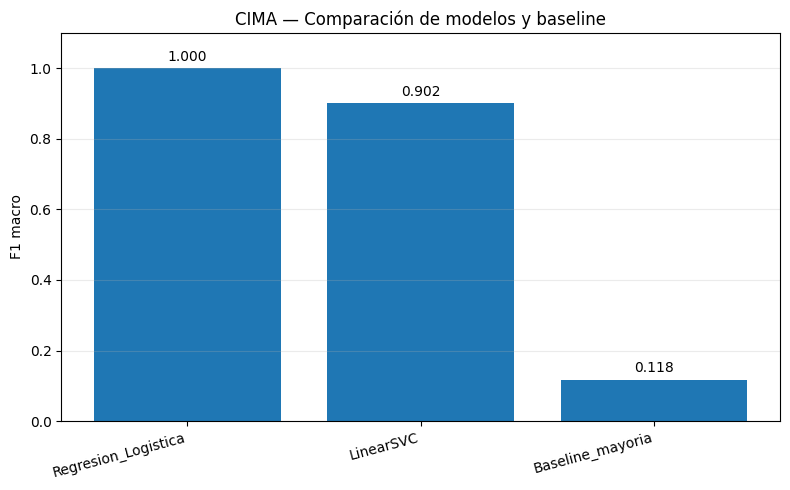

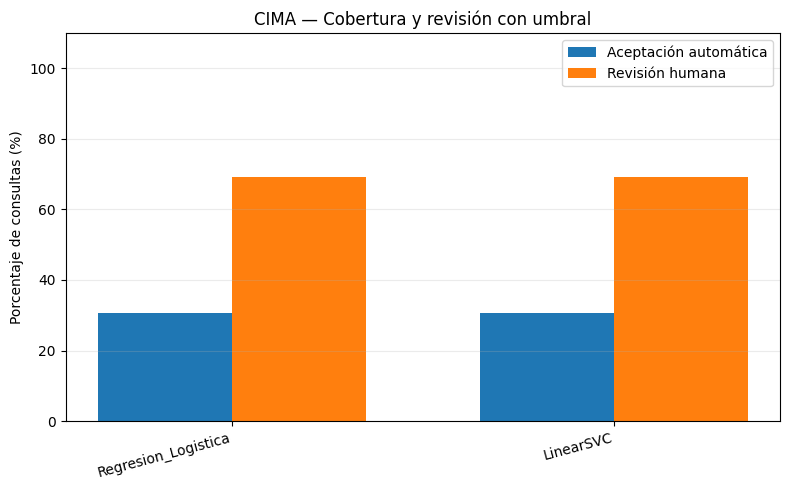

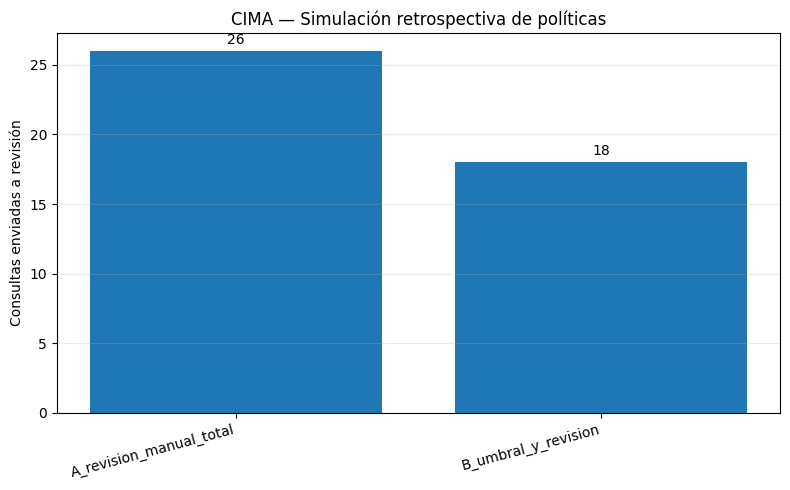

Tablas y gráficas exportadas a: /content/deep-learning-experiments/Actividad6/resultados
No se modificaron el dataset ni las predicciones originales.


In [14]:

from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Carpeta definitiva de resultados de la Actividad 6
FINAL_DIR = (
    Path("/content/deep-learning-experiments")
    / "Actividad6"
    / "resultados"
)
FINAL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Consolidar métricas iniciales
metrics_df.to_csv(
    FINAL_DIR / "metricas_modelos_baseline.csv",
    index=False,
    encoding="utf-8-sig"
)

threshold_df.to_csv(
    FINAL_DIR / "metricas_umbrales.csv",
    index=False,
    encoding="utf-8-sig"
)

comparaciones_df.to_csv(
    FINAL_DIR / "significancia_mcnemar.csv",
    index=False,
    encoding="utf-8-sig"
)

ab_df.to_csv(
    FINAL_DIR / "simulacion_ab.csv",
    index=False,
    encoding="utf-8-sig"
)

# 2. Gráfica comparativa de F1 macro
fig, ax = plt.subplots(figsize=(8, 5))

orden = metrics_df.sort_values(
    "f1_macro", ascending=False
)

barras = ax.bar(
    orden["modelo"],
    orden["f1_macro"]
)

ax.bar_label(barras, fmt="%.3f", padding=3)
ax.set_ylim(0, 1.1)
ax.set_ylabel("F1 macro")
ax.set_title("CIMA — Comparación de modelos y baseline")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

fig.savefig(
    FINAL_DIR / "comparacion_f1_macro.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 3. Cobertura automática frente a revisión
fig, ax = plt.subplots(figsize=(8, 5))

modelos = threshold_df["modelo"].tolist()
coberturas = (
    threshold_df["cobertura_total_test"].to_numpy() * 100
)
revision = 100 - coberturas

x = np.arange(len(modelos))
width = 0.35

ax.bar(x - width/2, coberturas, width, label="Aceptación automática")
ax.bar(x + width/2, revision, width, label="Revisión humana")

ax.set_xticks(x)
ax.set_xticklabels(modelos, rotation=15, ha="right")
ax.set_ylabel("Porcentaje de consultas (%)")
ax.set_ylim(0, 110)
ax.set_title("CIMA — Cobertura y revisión con umbral")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
fig.savefig(
    FINAL_DIR / "cobertura_revision_umbral.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# 4. Comparación de la carga de revisión en la simulación A/B
resumen_ab = (
    ab_df.groupby("politica", as_index=False)
    .agg(
        enviados_a_revision=("enviados_a_revision", "mean"),
        falsas_elegibilidades=("falsas_elegibilidades", "mean")
    )
)

fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    resumen_ab["politica"],
    resumen_ab["enviados_a_revision"]
)

ax.bar_label(barras, fmt="%.0f", padding=3)
ax.set_ylabel("Consultas enviadas a revisión")
ax.set_title("CIMA — Simulación retrospectiva de políticas")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

fig.savefig(
    FINAL_DIR / "simulacion_ab_revision.png",
    dpi=160,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Tablas y gráficas exportadas a:", FINAL_DIR)
print("No se modificaron el dataset ni las predicciones originales.")


In [15]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/deep-learning-experiments/Actividad6")
RESULTS = ROOT / "resultados"
INITIAL = RESULTS / "evaluacion_inicial"
ROC = INITIAL / "roc"
THRESHOLDS = INITIAL / "umbrales"
STATISTICS = INITIAL / "comparacion_estadistica_ab"

esperados = [
    RESULTS / "metricas_modelos_baseline.csv",
    RESULTS / "metricas_umbrales.csv",
    RESULTS / "significancia_mcnemar.csv",
    RESULTS / "simulacion_ab.csv",
    RESULTS / "comparacion_f1_macro.png",
    RESULTS / "cobertura_revision_umbral.png",
    RESULTS / "simulacion_ab_revision.png",
    INITIAL / "metricas_iniciales.csv",
    INITIAL / "predicciones_iniciales.csv",
    ROC / "roc_individual_vs_resto.png",
    ROC / "puntos_roc.csv",
    ROC / "cobertura_umbral.png",
    THRESHOLDS / "resumen_umbrales.csv",
    THRESHOLDS / "decisiones_umbral_test.csv",
    STATISTICS / "comparaciones_mcnemar.csv",
    STATISTICS / "simulacion_ab_politicas.csv",
]

print("VALIDACIÓN DE ARCHIVOS DE LA ACTIVIDAD 6\n")

faltantes = []

for archivo in esperados:
    existe = archivo.is_file()
    estado = "OK" if existe else "FALTA"
    print(f"[{estado}] {archivo.relative_to(ROOT)}")
    if not existe:
        faltantes.append(str(archivo.relative_to(ROOT)))

print("\nArchivos esperados:", len(esperados))
print("Archivos faltantes:", len(faltantes))

if faltantes:
    print("\nRevisa las rutas anteriores antes de publicar.")
else:
    print("\nVALIDACIÓN DE ESTRUCTURA SUPERADA.")

# Resumen de resultados para documentar la decisión
metricas = pd.read_csv(RESULTS / "metricas_modelos_baseline.csv")
umbrales = pd.read_csv(RESULTS / "metricas_umbrales.csv")
mcnemar = pd.read_csv(RESULTS / "significancia_mcnemar.csv")

display(
    metricas[
        ["modelo", "accuracy", "precision_macro",
         "recall_macro", "f1_macro", "falsas_elegibilidades"]
    ].round(4)
)

display(umbrales)
display(mcnemar)


VALIDACIÓN DE ARCHIVOS DE LA ACTIVIDAD 6

[OK] resultados/metricas_modelos_baseline.csv
[OK] resultados/metricas_umbrales.csv
[OK] resultados/significancia_mcnemar.csv
[OK] resultados/simulacion_ab.csv
[OK] resultados/comparacion_f1_macro.png
[OK] resultados/cobertura_revision_umbral.png
[OK] resultados/simulacion_ab_revision.png
[OK] resultados/evaluacion_inicial/metricas_iniciales.csv
[OK] resultados/evaluacion_inicial/predicciones_iniciales.csv
[OK] resultados/evaluacion_inicial/roc/roc_individual_vs_resto.png
[OK] resultados/evaluacion_inicial/roc/puntos_roc.csv
[OK] resultados/evaluacion_inicial/roc/cobertura_umbral.png
[OK] resultados/evaluacion_inicial/umbrales/resumen_umbrales.csv
[OK] resultados/evaluacion_inicial/umbrales/decisiones_umbral_test.csv
[OK] resultados/evaluacion_inicial/comparacion_estadistica_ab/comparaciones_mcnemar.csv
[OK] resultados/evaluacion_inicial/comparacion_estadistica_ab/simulacion_ab_politicas.csv

Archivos esperados: 16
Archivos faltantes: 0

VALIDA

,modelo,accuracy,precision_macro,recall_macro,f1_macro,falsas_elegibilidades
0,Regresion_Logistica,1.0000,1.0000,1.000,1.0000,0
1,LinearSVC,0.9615,0.9722,0.875,0.9020,1
2,Baseline_mayoria,0.3077,0.0769,0.250,0.1176,0


,modelo,puntaje,umbral_seleccionado,falsas_aceptaciones_oof,individuales_aceptados_test,total_individuales_test,falsas_aceptaciones_test,casos_enviados_a_revision_test,cobertura_total_test
0,Regresion_Logistica,probabilidad_individual,0.273113,0,8,8,0,18,0.307692
1,LinearSVC,margen_individual_vs_resto,0.504938,0,8,8,0,18,0.307692


,modelo_a,modelo_b,discordantes_a_acierta_b_falla,discordantes_a_falla_b_acierta,total_discordantes,mcnemar_p_exacta,significativo_0_05
0,Regresion_Logistica,LinearSVC,1,0,1,1.000000,False
1,Regresion_Logistica,Baseline_mayoria,18,0,18,0.000008,True
2,LinearSVC,Baseline_mayoria,17,0,17,0.000015,True


In [5]:
from pathlib import Path
import subprocess, sys, zipfile, shutil, os
from IPython.display import display, Image

REPO_URL = "https://github.com/alfredosalazar-ai/deep-learning-experiments.git"
REPO_DIR = Path("/content/deep-learning-experiments")

# Clonar o actualizar el repositorio público, si está disponible.
if not (REPO_DIR / ".git").exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
else:
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=False)

PROJECT_ROOT = REPO_DIR / "Actividad6"

# Fallback para la primera ejecución: se puede subir el ZIP del proyecto A6.
if not (PROJECT_ROOT / "fuentes" / "evaluacion.py").is_file():
    from google.colab import files
    print("Actividad6 aún no aparece en la rama main. Sube CIMA_Actividad6_GitHub.zip.")
    uploaded = files.upload()
    zip_name = next((name for name in uploaded if name.lower().endswith(".zip")), None)
    assert zip_name, "Debes cargar el ZIP que contiene la carpeta Actividad6."
    fallback = Path("/content/actividad6_cargada")
    fallback.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_name) as z:
        z.extractall(fallback)
    candidates = list(fallback.rglob("evaluacion.py"))
    assert candidates, "El ZIP no contiene fuentes/evaluacion.py."
    PROJECT_ROOT = candidates[0].parent.parent

assert (PROJECT_ROOT / "fuentes" / "evaluacion.py").is_file(), f"No se encontró evaluacion.py en {PROJECT_ROOT}"
print("Proyecto:", PROJECT_ROOT)
print("Python:", sys.version.split()[0])

Proyecto: /content/deep-learning-experiments/Actividad6
Python: 3.13.16


## 2. Instalar dependencias compatibles

Se fija scikit-learn 1.6.1 porque los modelos `.joblib` se serializaron con esa versión en la Actividad 5. Esto reduce los riesgos de incompatibilidad al cargar objetos persistidos.

In [6]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(PROJECT_ROOT / "requirements.txt")], check=True)

import sklearn, numpy, pandas, scipy
print("scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)
print("SciPy:", scipy.__version__)
assert sklearn.__version__ == "1.6.1", "Se esperaba scikit-learn 1.6.1 para compatibilidad con los modelos de A5."

KeyboardInterrupt: 

## 3. Ejecutar la evaluación

El script conserva los modelos originales y no modifica las particiones. Calcula la evaluación de prueba con los modelos A5, y estima umbrales mediante puntuaciones *out-of-fold* con validación cruzada OOF únicamente en entrenamiento. La prueba final no se utiliza para elegir umbrales.

In [ ]:
resultado = subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "fuentes" / "evaluacion.py")],
    cwd=PROJECT_ROOT,
    text=True,
    capture_output=True,
)
print(resultado.stdout)
if resultado.stderr:
    print("Mensajes del proceso:\n", resultado.stderr[-5000:])
if resultado.returncode != 0:
    raise RuntimeError(f"La evaluación terminó con código {resultado.returncode}")

## 4. Consultar métricas, umbrales y significancia

In [ ]:
import pandas as pd
OUT = PROJECT_ROOT / "resultados"

def mostrar_csv(nombre):
    path = OUT / nombre
    assert path.is_file(), f"No se generó {path}"
    print(f"\n### {nombre}")
    display(pd.read_csv(path, encoding="utf-8-sig"))

for nombre in [
    "metricas_actividad6.csv",
    "validacion_cruzada.csv",
    "analisis_umbrales.csv",
    "metricas_por_clase.csv",
    "comparacion_estadistica.csv",
    "simulacion_ab_politicas.csv",
]:
    mostrar_csv(nombre)

## 5. Visualizaciones generadas

In [ ]:
from IPython.display import display, Image
fig_dir = OUT / "graficas"
for img in sorted(fig_dir.glob("*.png")):
    print(img.name)
    display(Image(filename=str(img), width=760))

## 6. Exportar resultados para GitHub y el ZIP académico

El ZIP solo contiene los resultados generados por esta ejecución. Al cierre se integrarán a `Actividad6/resultados/` y se versionarán junto con el notebook y el informe técnico. La simulación A/B es retrospectiva y pareada; no constituye una prueba aleatoria con usuarios reales.

In [ ]:
from google.colab import files
import shutil

archivo_zip_resultados = "/content/CIMA_Actividad6_resultados.zip"
shutil.make_archive(archivo_zip_resultados[:-4], "zip", OUT)
print("Paquete generado:", archivo_zip_resultados)
files.download(archivo_zip_resultados)

## 7. Criterios de interpretación y control

- No interpretar el resultado perfecto observado anteriormente en 26 consultas sintéticas como precisión productiva.
- La puntuación de `LinearSVC` es un margen de decisión, no una probabilidad calibrada.
- El umbral se selecciona con OOF y debe evaluarse después sobre la prueba reservada.
- Las pruebas estadísticas sobre 26 casos tienen baja potencia; un valor p no demuestra equivalencia ni seguridad operativa.
- La comparación A/B se limita a una simulación offline sobre los mismos casos, no a un experimento real con usuarios.
- El modelo puede enrutar una consulta, pero no verifica folios, pagos, saldos ni estado de asignación. Esas validaciones deben continuar mediante reglas deterministas y controles humanos.